# Diabetes prediction

Can a few medical measurements predict diabetes?

**Data:** Pima Indians Diabetes dataset, 768 women with 8 features such as glucose, BMI, insulin and age. `Outcome = 1` means diabetes.

**Cleaning:** in this dataset a value of 0 for glucose, blood pressure, skin thickness, insulin or BMI means *not measured*. These zeros are treated as missing and filled with the median of the training data inside each model pipeline.

Every model below uses **the same stratified train/test split** (80/20, fixed seed). Imputation and scaling are fitted on the training data only. Models are compared with 5-fold cross-validation on the training set and scored once on the held-out test set. The shared code is in [`../src/disease_ml.py`](../src/disease_ml.py).

In [1]:
import sys
sys.path.insert(0, '../src')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import disease_ml as dm

pd.set_option('display.precision', 3)

## 1. Data

In [2]:
X, y = dm.load_diabetes()
LABELS = ['No diabetes', 'Diabetes']

print(f'{X.shape[0]:,} patients, {X.shape[1]} features')
X.head()

768 patients, 8 features


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [3]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,763.0,121.687,30.536,44.000,99.000,117.000,141.000,199.00
BloodPressure,733.0,72.405,12.382,24.000,64.000,72.000,80.000,122.00
SkinThickness,541.0,29.153,10.477,7.000,22.000,29.000,36.000,99.00
Insulin,394.0,155.548,118.776,14.000,76.250,125.000,190.000,846.00
BMI,757.0,32.457,6.925,18.200,27.500,32.300,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00


## 2. Exploration

How balanced are the two classes, and which features move with the target?

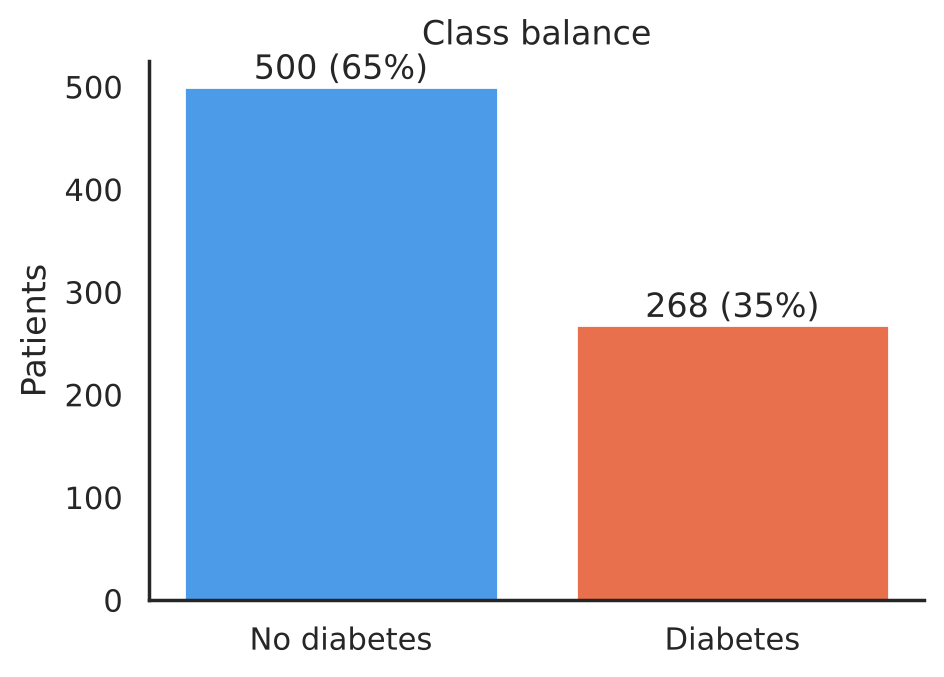

In [4]:
fig = dm.plot_class_balance(y, LABELS, 'Class balance')
dm.save(fig, 'diabetes_class_balance')

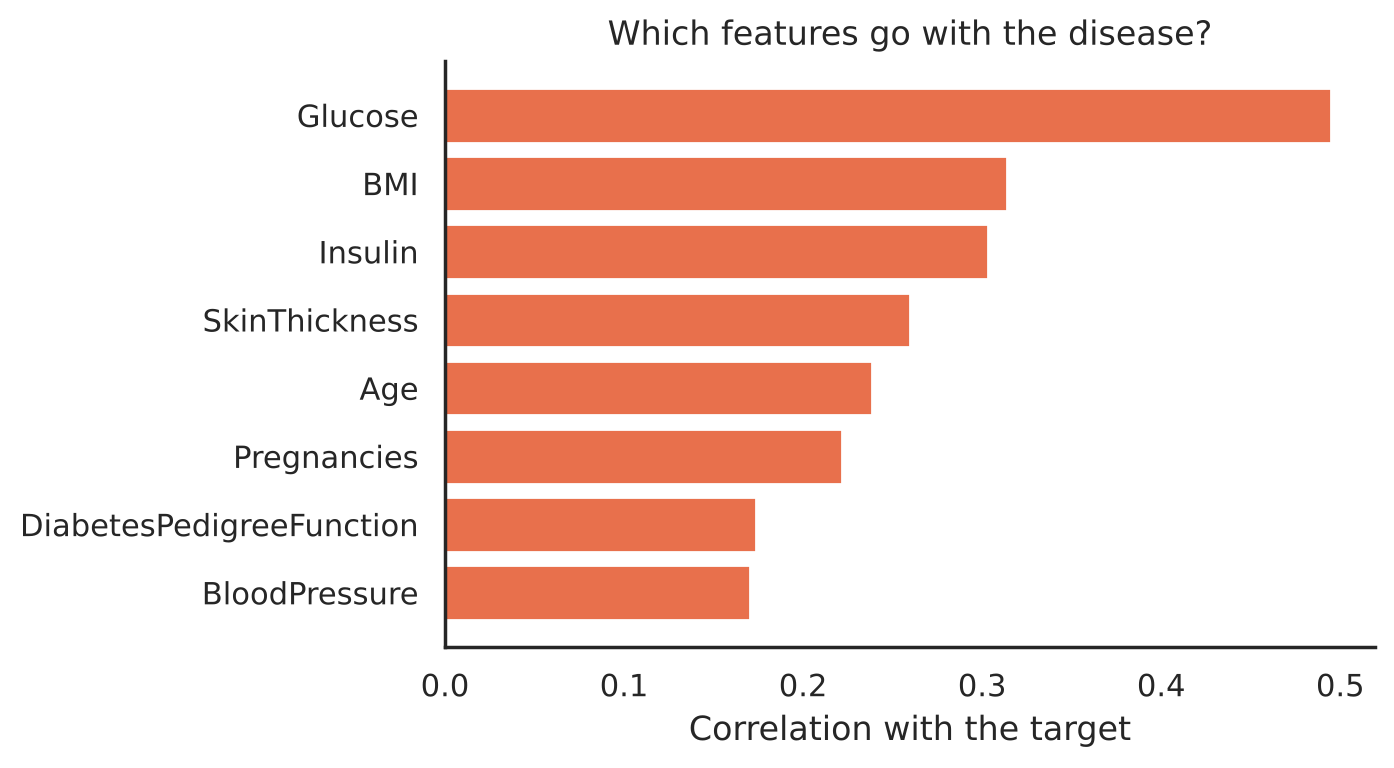

In [5]:
fig = dm.plot_correlation_with_target(X, y, 'Which features go with the disease?')
dm.save(fig, 'diabetes_correlation')

## 3. Classical models

In [6]:
X_train, X_test, y_train, y_test = dm.split(X, y)
models = dm.make_models(large=False, with_smote=True)

results, fitted = dm.evaluate_models(models, X_train, X_test, y_train, y_test)
results.sort_values('test_roc_auc', ascending=False)

,cv_accuracy,cv_accuracy_std,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,
Logistic regression,0.788,0.019,0.843,0.708,0.600,0.500,0.545,0.813
Random forest,0.769,0.017,0.827,0.753,0.682,0.556,0.612,0.812
Logistic regression + SMOTE,0.772,0.015,0.843,0.708,0.574,0.648,0.609,0.811
k-nearest neighbours,0.769,0.033,0.832,0.740,0.652,0.556,0.600,0.807
SVM (RBF kernel),0.780,0.014,0.833,0.740,0.652,0.556,0.600,0.796
Naive Bayes,0.762,0.028,0.828,0.701,0.567,0.630,0.596,0.765
Decision tree,0.728,0.018,0.769,0.760,0.639,0.722,0.678,0.762
Baseline (majority class),0.651,0.002,0.500,0.649,0.000,0.000,0.000,0.500


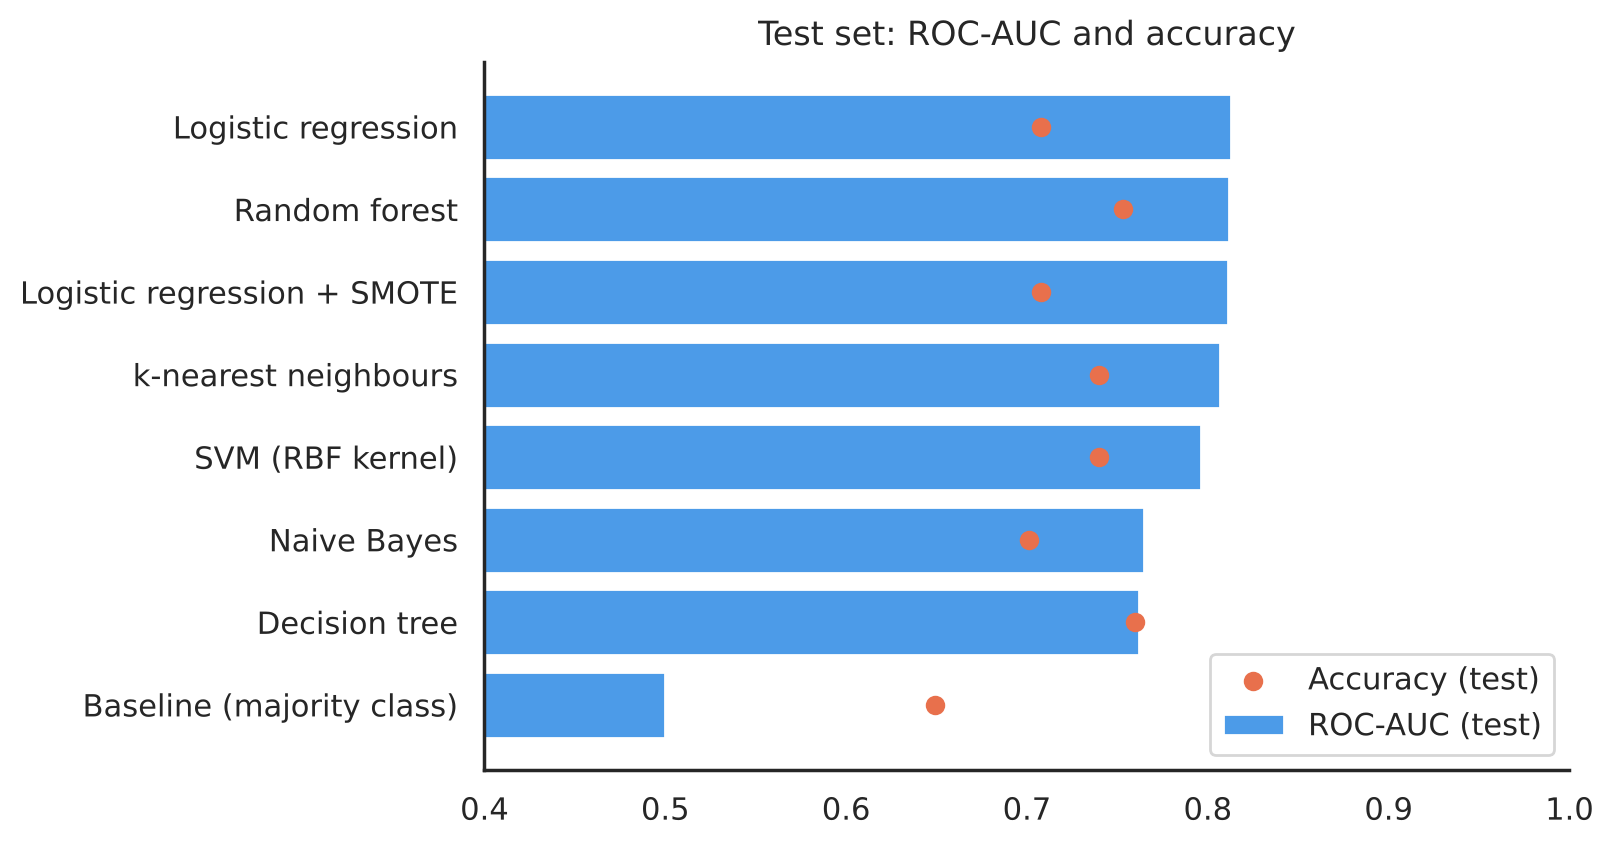

In [7]:
fig = dm.plot_model_comparison(results, 'Test set: ROC-AUC and accuracy')
dm.save(fig, 'diabetes_model_comparison')

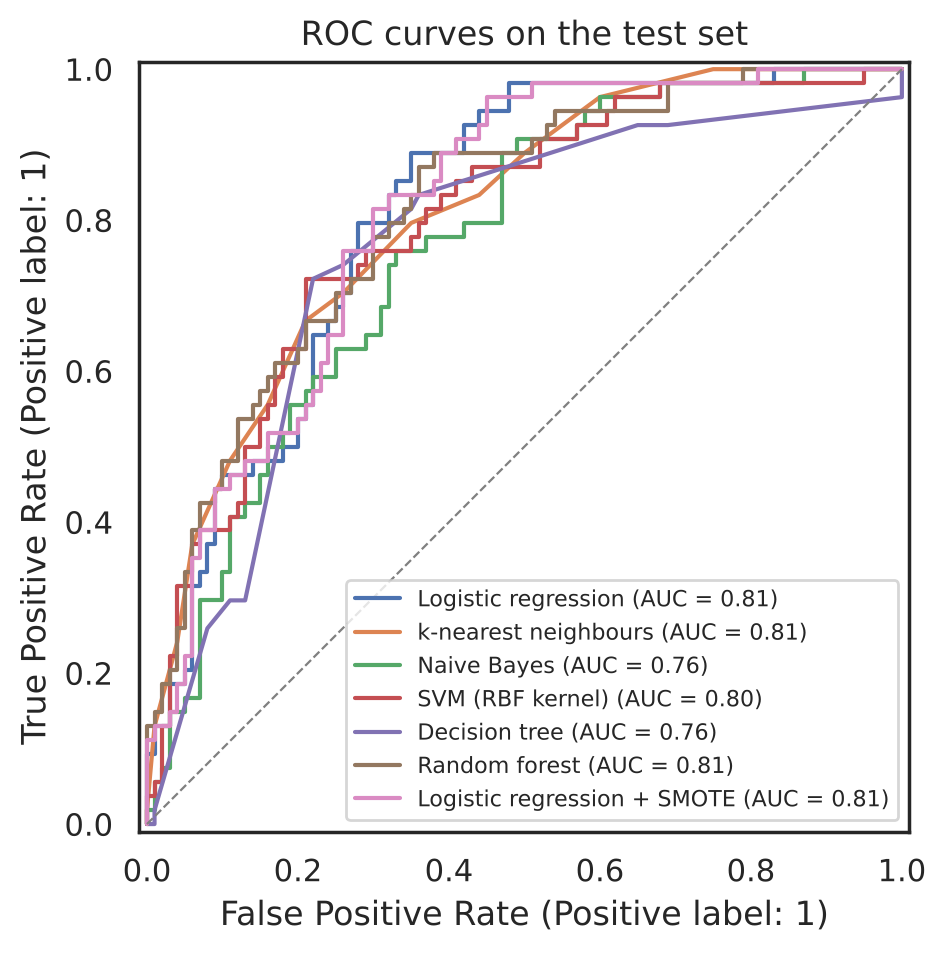

In [8]:
fig = dm.plot_roc_curves(fitted, X_test, y_test, 'ROC curves on the test set')
dm.save(fig, 'diabetes_roc_curves')

Best model by test ROC-AUC: Logistic regression


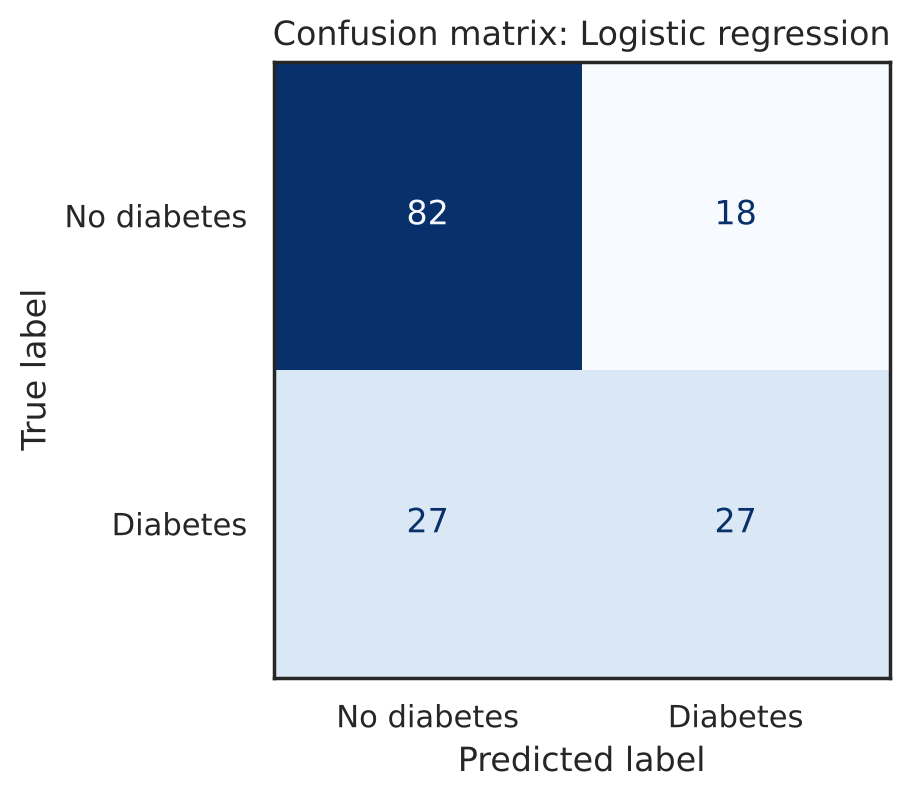

In [9]:
best = results.drop(index='Baseline (majority class)')['test_roc_auc'].idxmax()
fig = dm.plot_confusion(fitted[best], X_test, y_test, LABELS, f'Confusion matrix: {best}')
dm.save(fig, 'diabetes_confusion_best')
print('Best model by test ROC-AUC:', best)

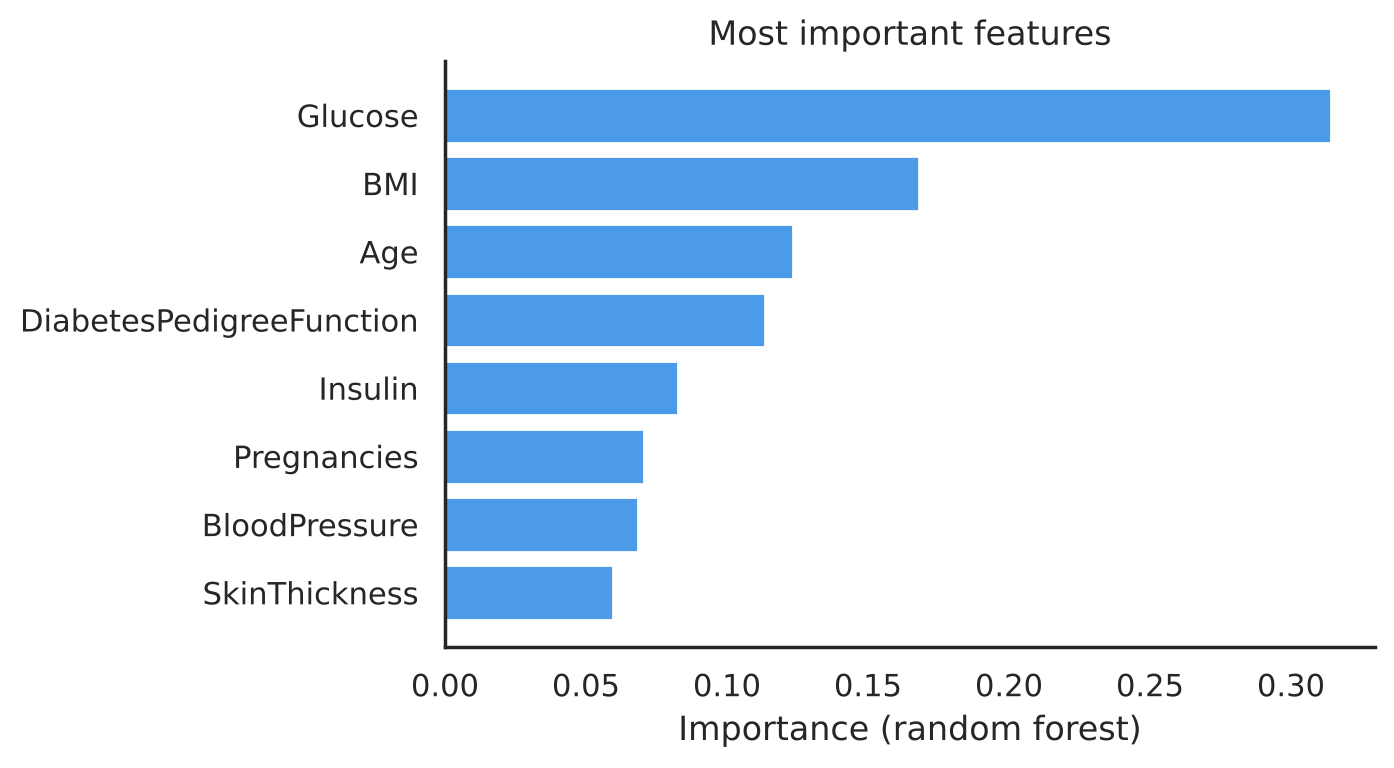

In [10]:
fig = dm.plot_feature_importance(fitted['Random forest'], X.columns, 'Most important features')
dm.save(fig, 'diabetes_feature_importance')

## 4. Neural network

A small Keras network (16 → 8 → 1 neurons, dropout, early stopping) trained on the same split.

I0000 00:00:1795493449.181473   10778 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795493450.588342   10778 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


test_accuracy      0.708
test_precision     0.600
test_recall        0.500
test_f1            0.545
test_roc_auc       0.800
epochs_trained    60.000
dtype: float64

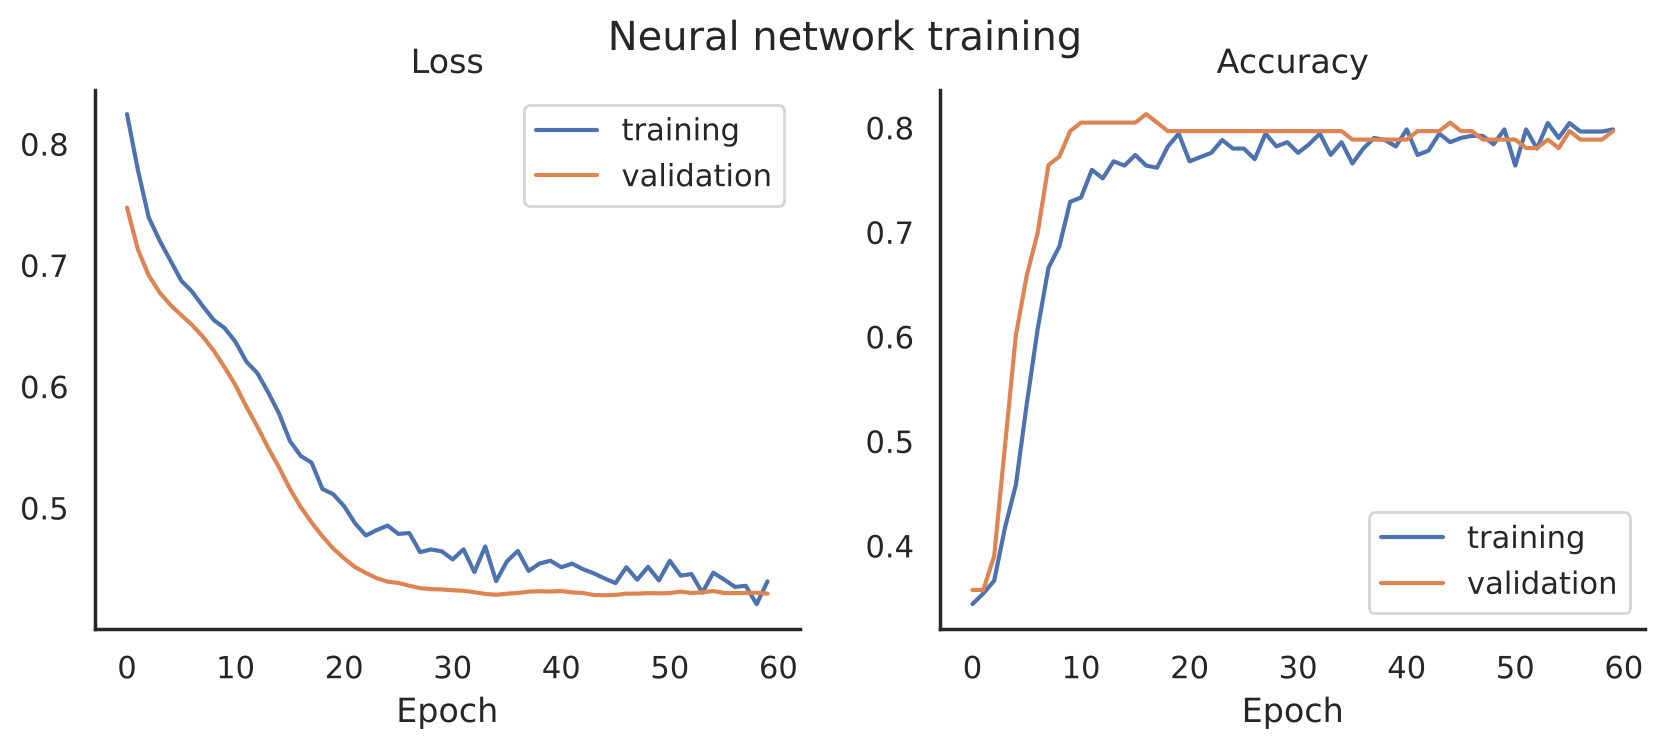

In [11]:
ann, history, ann_metrics = dm.train_ann(X_train, X_test, y_train, y_test)
fig = dm.plot_history(history, 'Neural network training')
dm.save(fig, 'diabetes_ann_training')
pd.Series(ann_metrics)

## 5. Summary table

In [12]:
summary = results[['cv_accuracy', 'cv_roc_auc', 'test_accuracy', 'test_recall', 'test_f1', 'test_roc_auc']].copy()
summary.loc['Neural network (Keras)'] = [None, None, ann_metrics['test_accuracy'], ann_metrics['test_recall'],
                                         ann_metrics['test_f1'], ann_metrics['test_roc_auc']]
summary = summary.sort_values('test_roc_auc', ascending=False)
dm.RESULTS_DIR.mkdir(exist_ok=True)
summary.to_csv(dm.RESULTS_DIR / 'diabetes_results.csv')
summary

,cv_accuracy,cv_roc_auc,test_accuracy,test_recall,test_f1,test_roc_auc
model,,,,,,
Logistic regression,0.788,0.843,0.708,0.500,0.545,0.813
Random forest,0.769,0.827,0.753,0.556,0.612,0.812
Logistic regression + SMOTE,0.772,0.843,0.708,0.648,0.609,0.811
k-nearest neighbours,0.769,0.832,0.740,0.556,0.600,0.807
Neural network (Keras),NaN,NaN,0.708,0.500,0.545,0.800
SVM (RBF kernel),0.780,0.833,0.740,0.556,0.600,0.796
Naive Bayes,0.762,0.828,0.701,0.630,0.596,0.765
Decision tree,0.728,0.769,0.760,0.722,0.678,0.762
Baseline (majority class),0.651,0.500,0.649,0.000,0.000,0.500


## 6. Conclusion

- **Best models:** logistic regression, random forest and logistic regression with SMOTE all reach a test ROC-AUC of about **0.81**, with 71–75 % accuracy against 65 % for always predicting "no diabetes".
- **Recall is the weak point:** the standard models find only about **half** of the women with diabetes. Balancing the training data with SMOTE raises recall from 50 % to **65 %** at the same ROC-AUC, at the price of more false alarms. For screening that trade is usually worth it.
- **Decision tree:** it has the best test accuracy (76 %) but the weakest cross-validation score (73 %), so its good test result is most likely luck on this particular split.
- **Most important features:** glucose, BMI, age and the diabetes pedigree function (family history).
- **Neural network:** ROC-AUC 0.80, no better than logistic regression.